# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Савков Олександр'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 6      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 6, файл lr6_варіант_06.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
TYPE_OF_TASK = 'класифікація'
TYPE_WHY = 'ціль відтік має два значення, 1 або 0, і модель має дати кожному клієнтові оцінку ризику класу 1'

METRIC = 'AUC'
METRIC_WHY = ('відтік за описом набору становить 15–30 % клієнтів, тож модель «ніхто не піде» матиме точність 70–85 % без жодної користі, '
              'а AUC не залежить від порога і показує, чи ставить модель тих, хто піде, вище за тих, хто лишиться')

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'
CV_WHY = ('на кожного клієнта один рядок, тому групова схема не потрібна, стратифікація тримає однакову частку відтоку в кожній згортці, '
          'а 4 повтори дають 20 чисел, з яких видно розкид оцінки')

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')
for val, why in [(TYPE_OF_TASK, TYPE_WHY), (METRIC, METRIC_WHY), (CV_SCHEME, CV_WHY)]:
    print('%s: %s' % (val, why))

рішення зафіксовані
класифікація: ціль відтік має два значення, 1 або 0, і модель має дати кожному клієнтові оцінку ризику класу 1
AUC: відтік за описом набору становить 15–30 % клієнтів, тож модель «ніхто не піде» матиме точність 70–85 % без жодної користі, а AUC не залежить від порога і показує, чи ставить модель тих, хто піде, вище за тих, хто лишиться
стратифікована 5-кратна, 4 повтори: на кожного клієнта один рядок, тому групова схема не потрібна, стратифікація тримає однакову частку відтоку в кожній згортці, а 4 повтори дають 20 чисел, з яких видно розкид оцінки


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.286

типи стовпців: {'object': 13, 'float64': 8, 'int64': 5}


In [6]:
info = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'унікальних': raw.nunique(),
    '% пропусків': (100 * raw.isna().mean()).round(1),
    'приклад': raw.apply(lambda s: s.dropna().iloc[0]),
}).rename_axis('стовпець').sort_values('% пропусків', ascending=False)
display(info)
print('стовпців нечислового типу: %d' % sum(not pd.api.types.is_numeric_dtype(raw[c]) for c in raw.columns))

,тип,унікальних,% пропусків,приклад
стовпець,,,,
сума_повернення_депозиту,float64,341,71.4,100.25
дата_розірвання,object,286,71.4,2025-04-07
середній_час_відповіді_хв,float64,263,33.3,13.2
трафік_ГБ,object,982,5.0,146.0
щомісячний_платіж,object,1128,4.0,306.12
аварій_на_ділянці_за_квартал,float64,5,3.0,1.0
id_клієнта,object,1200,0.0,K60000
оцінка_ризику_менеджером,float64,5,0.0,5.0
дата_підключення,object,582,0.0,2024-11-03


стовпців нечислового типу: 13


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
pay = raw['щомісячний_платіж']
text_pay = pay.notna() & ~pay.astype(str).str.fullmatch(r'-?\d+(\.\d+)?', na=False)
print('щомісячний_платіж: текст замість числа в %d рядках, напр. %s' % (text_pay.sum(), pay[text_pay].head(4).tolist()))

excel = raw['трафік_ГБ'].astype(str).str.match(r'\d{4}-\d{2}-\d{2}', na=False)
print('трафік_ГБ: дата замість числа в %d рядках, поруч той самий трафік у МБ' % excel.sum())
display(raw.loc[excel, ['трафік_ГБ', 'трафік_МБ']])

no_time = raw['середній_час_відповіді_хв'].isna()
display(pd.crosstab(raw['кількість_звернень_у_підтримку'], no_time.map({True: 'час пропущено', False: 'час є'})))
print('відтік: де час пропущено %.3f, де час є %.3f' % (raw.loc[no_time, TARGET].mean(), raw.loc[~no_time, TARGET].mean()))

щомісячний_платіж: текст замість числа в 25 рядках, напр. ['277.16 грн', '298.44 грн', '676.6 грн', '305.51 грн']
трафік_ГБ: дата замість числа в 3 рядках, поруч той самий трафік у МБ


,трафік_ГБ,трафік_МБ
191,1900-01-24 00:00:00,510694.3
373,1900-01-10 00:00:00,104568.4
400,1900-01-09 00:00:00,291339.6


середній_час_відповіді_хв,час пропущено,час є
кількість_звернень_у_підтримку,,
0,400,0
1,0,420
2,0,272
3,0,78
4,0,21
5,0,7
6,0,2


відтік: де час пропущено 0.217, де час є 0.320


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'
PROBLEM_MNAR           = 'середній_час_відповіді_хв'
MNAR_MEANING           = ('пропуск стоїть рівно в тих клієнтів, які жодного разу не зверталися в підтримку, '
                          'тобто означає «звернень не було», а не загублене значення, і такі клієнти йдуть рідше')

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        if isinstance(v, datetime.date):
            return np.nan
        if isinstance(v, (int, float, np.integer, np.floating)):
            return float(v)
        t = str(v).strip()
        if re.fullmatch(r'\d{4}-\d{2}-\d{2}([ T]\d{2}:\d{2}(:\d{2})?)?', t):
            return np.nan
        m = re.search(r'-?\d+(?:[.,]\d+)?', t)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується
SEX = {'ч': 'ч', 'чол': 'ч', 'ж': 'ж', 'жін': 'ж'}
EPOCH = pd.Timestamp('2020-01-01')

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if c.startswith('дата_'):
            X[c] = (pd.to_datetime(s, errors='coerce') - EPOCH).dt.days.astype(float)
            how = 'дата -> днів від 2020-01-01'
        elif pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            how = 'число'
        elif s.dropna().astype(str).str.match(r'\s*-?\d').mean() > 0.8:
            X[c] = to_number(s)
            how = 'текст -> число'
        else:
            v = s.astype(str).str.strip().str.lower().where(s.notna())
            X[c] = (v.map(SEX) if c == 'стать' else v).astype('category')
            how = 'категорія'
        log.append({'стовпець': c, 'рішення': how, 'NaN після': int(X[c].isna().sum())})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,рішення,NaN після
0,вік,число,0
1,стать,категорія,0
2,місто,категорія,0
3,філія,категорія,0
4,тариф,категорія,0
5,тип_підключення,категорія,0
6,спосіб_оплати,категорія,0
7,автоплатіж,категорія,0
8,кількість_послуг,число,0
9,місяців_обслуговування,число,0


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    num = [c for c in X.columns if c not in cat]
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
    ])
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.977


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.977 ± 0.006
час      : 0.2 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = ('AUC %.3f на реальних даних майже напевно означає витік, а не добру модель: з двох причин такого числа, '
                  '«задача справді проста» і «в ознаках уже є відповідь», спрацювала друга, бо намір клієнта піти '
                  'за звичайними ознаками договору не вгадується майже без помилок' % auc_naive.mean())
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0.977 на реальних даних майже напевно означає витік, а не добру модель: з двох причин такого числа, «задача справді проста» і «в ознаках уже є відповідь», спрацювала друга, бо намір клієнта піти за звичайними ознаками договору не вгадується майже без помилок


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        if filled.sum() < min_group or (~filled).sum() < min_group:
            continue
        a = roc_auc_score(y, filled.astype(int))
        rows.append({'ознака': c, 'заповнено': int(filled.sum()),
                     'частка_відтоку_де_заповнено': round(float(y[filled].mean()), 3),
                     'частка_відтоку_де_пропуск': round(float(y[~filled].mean()), 3),
                     'показник': round(max(a, 1 - a), 3)})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))
print('не перевірено, бо пропусків менше за min_group: %d стовпців' % (raw.shape[1] - 1 - len(scan)))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
4,дата_розірвання,343,1.000,0.000,1.000
5,сума_повернення_депозиту,343,1.000,0.000,1.000
3,середній_час_відповіді_хв,800,0.320,0.217,0.556
1,трафік_ГБ,1140,0.291,0.183,0.513
0,щомісячний_платіж,1152,0.281,0.396,0.511
2,аварій_на_ділянці_за_квартал,1164,0.290,0.167,0.509


не перевірено, бо пропусків менше за min_group: 19 стовпців


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = ['дата_розірвання', 'сума_повернення_депозиту']
TARGET_LEAK_WHY = {
    'дата_розірвання': 'дату записують у день розірвання, а в момент прогнозу договір ще чинний',
    'сума_повернення_депозиту': 'депозит повертають лише після закриття договору, тож суму вносять уже після відтоку',
}
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)
for c in TARGET_LEAK:
    print('   %s: %s' % (c, TARGET_LEAK_WHY[c]))

цільовий витік: ['дата_розірвання', 'сума_повернення_депозиту']
   дата_розірвання: дату записують у день розірвання, а в момент прогнозу договір ще чинний
   сума_повернення_депозиту: депозит повертають лише після закриття договору, тож суму вносять уже після відтоку


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.976 ± 0.007


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


In [18]:
HUMAN_LEAK = ['оцінка_ризику_менеджером']
HUMAN_LEAK_WHY = ('оцінку від 1 до 5 ставить менеджер, який уже бачив поведінку клієнта, тобто це м’яка версія відповіді; '
                  'детектор її не бачить, бо поле заповнене в усіх %d клієнтів і групи пропусків просто немає, '
                  'а за змістом оцінка не є наслідком розірвання, тож у чек-лист цільового витоку вона теж не потрапляє' % len(raw))

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
display(raw.groupby(HUMAN_LEAK[0])[TARGET].agg(клієнтів='size', відтік='mean').round(3))
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

,клієнтів,відтік
оцінка_ризику_менеджером,,
1.0,250,0.000
2.0,372,0.019
3.0,285,0.267
4.0,173,0.815
5.0,120,0.992


після вилучення оцінок людини: 21 ознак, AUC 0.829 ± 0.023


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,клієнтів,відтік
філія,,
Ф-01 Центр,233,0.275
Ф-02 Захід,186,0.296
Ф-03 Схід,170,0.265
Ф-04 Південь,194,0.294
Ф-05 Північ,204,0.328
Ф-06 Приміська,213,0.258


дата_підключення,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4
клієнтів,146.000,127.00,155.000,178.00,146.000,166.000,132.000,150.000
відтік,0.178,0.22,0.213,0.23,0.219,0.404,0.394,0.427


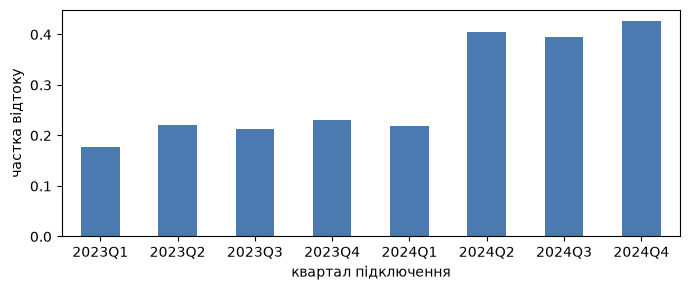

In [19]:
by_branch = raw.groupby('філія')[TARGET].agg(клієнтів='size', відтік='mean').round(3)
quarter = pd.to_datetime(raw['дата_підключення']).dt.to_period('Q').astype(str)
by_quarter = raw.groupby(quarter)[TARGET].agg(клієнтів='size', відтік='mean').round(3)
display(by_branch)
display(by_quarter.T)

ax = by_quarter['відтік'].plot(kind='bar', figsize=(7, 3), color='#4a7ab0')
ax.set_xlabel('квартал підключення')
ax.set_ylabel('частка відтоку')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'дата_підключення'
assert SUSPECT in ('філія', 'дата_підключення')

BREAK = pd.Timestamp('2024-04-01')
source = (pd.to_datetime(raw[SUSPECT]) >= BREAK).astype(int)
print('підключені з %s: %d клієнтів, %.3f вибірки' % (BREAK.date(), source.sum(), source.mean()))

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

mix = pd.DataFrame({'швидкість від 400 Мбіт': raw['швидкість_тарифу_Мбіт'] >= 400,
                    'оптика': raw['тип_підключення'] == 'оптика',
                    'автоплатіж': raw['автоплатіж'] == 'так'}).groupby(source).mean().round(3)
mix.index = ['до %s' % BREAK.date(), 'з %s' % BREAK.date()]
display(mix)

підключені з 2024-04-01: 448 клієнтів, 0.373 вибірки


ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.752
ті самі ознаки передбачають ВІДТІК  : AUC 0.812 ± 0.022


,швидкість від 400 Мбіт,оптика,автоплатіж
до 2024-04-01,0.197,0.703,0.422
з 2024-04-01,0.446,0.848,0.614


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.977
2. мінус цільовий витік,22,0.976
3. мінус оцінки людини,21,0.829
4. мінус артефакт збору,20,0.812


чесне число: 0.812 ± 0.022


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'
DECISION_WHY = ('відтік стрибком зростає з %.3f у 2024Q1 до %.3f у 2024Q2 і по обидва боки тримається рівним, тобто змінилось правило обліку, '
                'а не поведінка клієнтів, і модель із датою вчилась би вгадувати правило, однакове для всіх нових клієнтів; '
                'артефакт це повністю не знімає, бо чесні ознаки вгадують період з AUC %.3f через швидкість тарифу, оптику й автоплатіж, '
                'тому число без дати я подаю як чесне, а залишковий артефакт називаю у звіті окремо'
                % (by_quarter.loc['2024Q1', 'відтік'], by_quarter.loc['2024Q2', 'відтік'], auc_src.mean()))
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — відтік стрибком зростає з 0.219 у 2024Q1 до 0.404 у 2024Q2 і по обидва боки тримається рівним, тобто змінилось правило обліку, а не поведінка клієнтів, і модель із датою вчилась би вгадувати правило, однакове для всіх нових клієнтів; артефакт це повністю не знімає, бо чесні ознаки вгадують період з AUC 0.752 через швидкість тарифу, оптику й автоплатіж, тому число без дати я подаю як чесне, а залишковий артефакт називаю у звіті окремо


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.812,0.022,0.2
одне дерево,0.709,0.033,0.2
випадковий ліс,0.825,0.019,3.8
гістограмний бустинг,0.818,0.019,41.1


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)
    return d.mean(), 1.96 * d.std(ddof=1) / np.sqrt(len(d))


gains = {}
base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    gains[name] = (m, h)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0133 ± 0.0058   значуще


гістограмний бустинг   проти логістичної: +0.0058 ± 0.0076   у межах шуму


In [25]:
CHOSEN_MODEL = 'випадковий ліс'
CHOSEN_WHY = ('за якістю ліс кращий за логістичну регресію на %+.4f ± %.4f, інтервал не накриває нуль, а бустинг дав %+.4f ± %.4f, тобто в межах шуму; '
              'за обсягом даних %d клієнтів на %d ознак вистачає і лісу; за природою даних ознаки змішаних типів, і дерева самі беруть пороги та взаємодії; '
              'за вартістю 20 навчань лісу забрали %.1f с, бустингу %.1f с; у інтерпретованості ліс програє регресії, і її повертають інструменти другої частини'
              % (gains['випадковий ліс'] + gains['гістограмний бустинг']
                 + (len(X4), X4.shape[1], cmp_models.loc['випадковий ліс', 'с на 100 навчань'],
                    cmp_models.loc['гістограмний бустинг', 'с на 100 навчань'])))
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: випадковий ліс — за якістю ліс кращий за логістичну регресію на +0.0133 ± 0.0058, інтервал не накриває нуль, а бустинг дав +0.0058 ± 0.0076, тобто в межах шуму; за обсягом даних 1200 клієнтів на 20 ознак вистачає і лісу; за природою даних ознаки змішаних типів, і дерева самі беруть пороги та взаємодії; за вартістю 20 навчань лісу забрали 3.8 с, бустингу 41.1 с; у інтерпретованості ліс програє регресії, і її повертають інструменти другої частини


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
FEATURE_IDEAS = {
    'перші_24_місяці': 'перші два роки клієнт ще не прив’язаний до провайдера і, найпевніше, сидить на першому договорі, тому йде частіше',
    'знижка_новому': 'знижка новому клієнтові зазвичай акційна: коли вона скінчиться, ціна зросте і він піде, а давньому знижка дає причину лишитись',
    'гривень_за_мбіт': 'хто платить більше за кожен мегабіт, той переплачує і першим перейде до дешевшого провайдера',
}

def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    new = (F['місяців_обслуговування'] <= 24).astype(float)
    F['перші_24_місяці'] = new
    F['знижка_новому'] = F['знижка_відсоток'] * new
    F['гривень_за_мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))
for k, v in FEATURE_IDEAS.items():
    print('   %s: %s' % (k, v))

було 20 ознак, стало 23
   перші_24_місяці: перші два роки клієнт ще не прив’язаний до провайдера і, найпевніше, сидить на першому договорі, тому йде частіше
   знижка_новому: знижка новому клієнтові зазвичай акційна: коли вона скінчиться, ціна зросте і він піде, а давньому знижка дає причину лишитись
   гривень_за_мбіт: хто платить більше за кожен мегабіт, той переплачує і першим перейде до дешевшого провайдера


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.838 ± 0.019
приріст проти базового набору: +0.0258 ± 0.0056   значуще


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
feat_gain = paired(base, auc5)
rf_gain = gains['випадковий ліс']
FEATURES_VS_MODEL = ('більше дали нові ознаки: три ознаки підняли AUC логістичної регресії на %+.4f ± %.4f, '
                     'а заміна регресії на ліс без нових ознак дала %+.4f ± %.4f; ознаки нічого не коштують у часі, '
                     '20 навчань регресії тривають %.1f с, лісу %.1f с'
                     % (feat_gain + rf_gain + (cmp_models.loc['логістична регресія', 'с на 100 навчань'],
                                               cmp_models.loc['випадковий ліс', 'с на 100 навчань'])))
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

більше дали нові ознаки: три ознаки підняли AUC логістичної регресії на +0.0258 ± 0.0056, а заміна регресії на ліс без нових ознак дала +0.0133 ± 0.0058; ознаки нічого не коштують у часі, 20 навчань регресії тривають 0.2 с, лісу 3.8 с


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.837
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

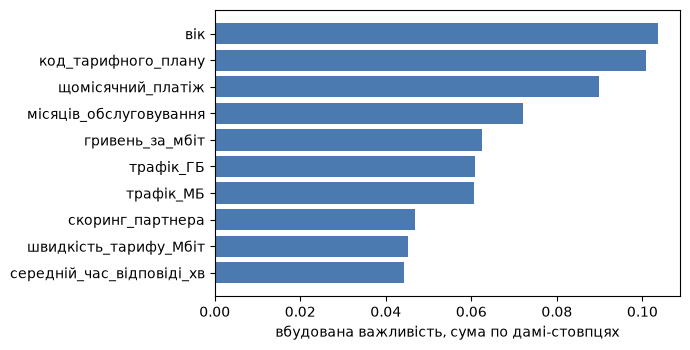

In [30]:
from sklearn.base import clone

pr = model.named_steps['prep']
num_cols = list(pr.transformers_[0][2])
cat_cols = list(pr.transformers_[1][2])
levels = pr.named_transformers_['cat'].named_steps['oh'].categories_
owner = num_cols + [c for c, lv in zip(cat_cols, levels) for _ in lv]
assert len(owner) == len(pr.get_feature_names_out())

gini_imp = (pd.Series(model.named_steps['clf'].feature_importances_, index=owner)
            .groupby(level=0).sum().sort_values(ascending=False))
top10 = gini_imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(top10.index, top10.values, color='#4a7ab0')
ax.set_xlabel('вбудована важливість, сума по дамі-стовпцях')
plt.tight_layout()
plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.068979
щомісячний_платіж,0.035834
знижка_новому,0.017113
трафік_МБ,0.008640
швидкість_тарифу_Мбіт,0.008564
місяців_обслуговування,0.008115
трафік_ГБ,0.005770
гривень_за_мбіт,0.004543
кількість_послуг,0.002471
знижка_відсоток,0.002216


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
imp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp,
                    'унікальних значень': FINAL_X.nunique()}).sort_values('вбудована', ascending=False).round(4)
display(imp)

,вбудована,перестановочна,унікальних значень
вік,0.1036,0.0690,60
код_тарифного_плану,0.1009,-0.0047,40
щомісячний_платіж,0.0899,0.0358,1127
місяців_обслуговування,0.0721,0.0081,84
гривень_за_мбіт,0.0626,0.0045,1141
трафік_ГБ,0.0608,0.0058,979
трафік_МБ,0.0605,0.0086,1200
скоринг_партнера,0.0468,0.0007,1200
швидкість_тарифу_Мбіт,0.0451,0.0086,9
середній_час_відповіді_хв,0.0442,-0.0029,263


In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану'
fake_rank = list(imp.index).index(FAKE_IMPORTANT) + 1
FAKE_IMPORTANT_WHY = ('за вбудованою важливістю ознака на %d-му місці (%.4f), а перестановочна %+.4f, тобто без неї модель на перевірковій частині не гірша; '
                      '%d рівнів після одиничного кодування дають стільки ж дамі-стовпців і можливих розбиттів, і дерево на навчальних даних '
                      'майже завжди знаходить серед них таке, що трохи зменшує неоднорідність, а ці дрібні виграші сумуються, хоча зв’язку з відтоком немає'
                      % (fake_rank, imp.loc[FAKE_IMPORTANT, 'вбудована'], imp.loc[FAKE_IMPORTANT, 'перестановочна'],
                         FINAL_X[FAKE_IMPORTANT].nunique()))
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)
print(FAKE_IMPORTANT_WHY)

хибно важлива ознака: код_тарифного_плану
за вбудованою важливістю ознака на 2-му місці (0.1009), а перестановочна -0.0047, тобто без неї модель на перевірковій частині не гірша; 40 рівнів після одиничного кодування дають стільки ж дамі-стовпців і можливих розбиттів, і дерево на навчальних даних майже завжди знаходить серед них таке, що трохи зменшує неоднорідність, а ці дрібні виграші сумуються, хоча зв’язку з відтоком немає


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
num_final = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
corr = FINAL_X[num_final].corr().abs()
pairs = [(a, b, round(corr.loc[a, b], 4)) for i, a in enumerate(num_final) for b in num_final[i + 1:]
         if corr.loc[a, b] > 0.97]
print('пари з |r| > 0.97:', pairs)

пари з |r| > 0.97: [('трафік_ГБ', 'трафік_МБ', np.float64(0.9997))]


In [35]:
DUP_PAIR = ['трафік_ГБ', 'трафік_МБ']
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

keep = [c for c in FINAL_X.columns if c != DUP_PAIR[1]]
model_one = make_pipe(FINAL_X[keep], clone(FINAL_CLF)).fit(Xtr[keep], ytr)
perm_one = permutation_importance(model_one, Xte[keep], yte, n_repeats=10,
                                  random_state=SEED, scoring='roc_auc')
dup_alone = pd.Series(perm_one.importances_mean, index=keep)[DUP_PAIR[0]]
print('без %s:' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], dup_alone))

у повній моделі:
   трафік_ГБ                    +0.0058
   трафік_МБ                    +0.0086


без трафік_МБ:
   трафік_ГБ                    +0.0233


In [36]:
DUP_EXPLANATION = ('у повній моделі %s має %+.4f, а %s %+.4f, і обидві виглядають майже непотрібними; без %s важливість %s стає %+.4f, '
                   'бо коли той самий трафік записано у двох колонках, перемішування однієї нічого не ламає, модель бере його з другої; '
                   'метод відповідає точно на своє питання «наскільки гірше без цієї ознаки», хибним є лише висновок «нуль, отже викинути обидві»'
                   % (DUP_PAIR[0], perm_imp[DUP_PAIR[0]], DUP_PAIR[1], perm_imp[DUP_PAIR[1]], DUP_PAIR[1], DUP_PAIR[0], dup_alone))
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

у повній моделі трафік_ГБ має +0.0058, а трафік_МБ +0.0086, і обидві виглядають майже непотрібними; без трафік_МБ важливість трафік_ГБ стає +0.0233, бо коли той самий трафік записано у двох колонках, перемішування однієї нічого не ламає, модель бере його з другої; метод відповідає точно на своє питання «наскільки гірше без цієї ознаки», хибним є лише висновок «нуль, отже викинути обидві»


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

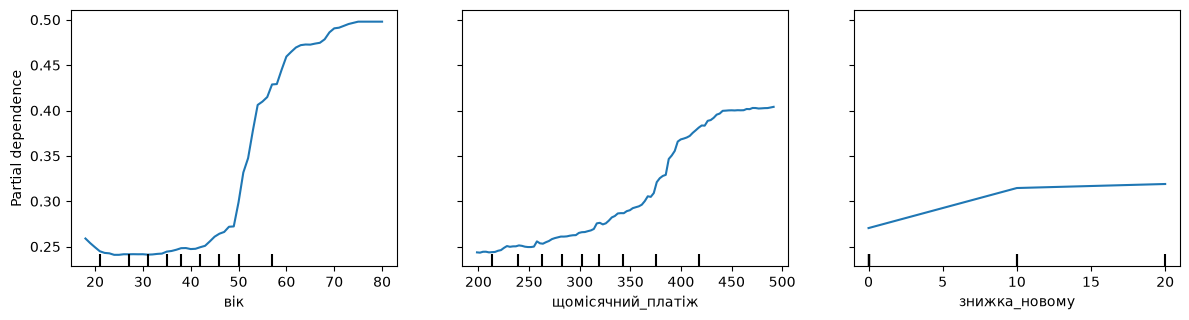

три ознаки: ['вік', 'щомісячний_платіж', 'знижка_новому'] ; PDP на 1152 клієнтах, у яких вони заповнені


вік: ризик трохи спадає з 0.259 у 18 років до мінімуму 0.241 у 24, далі зростає до 0.498 у 80; щомісячний_платіж: що дорожчий рахунок, то вищий ризик, від 0.244 при 199 грн до 0.404 при 492 грн, найкрутіше біля 385 грн; знижка_новому: ризик зростає з 0.270 без знижки до 0.319 при 20, але давній клієнт такого значення мати не може, тож частина кривої описує неіснуючі поєднання


In [37]:
from sklearn.inspection import PartialDependenceDisplay

TOP3 = [c for c in perm_imp.index if str(FINAL_X[c].dtype) != 'category'][:3]
sub = FINAL_X.dropna(subset=TOP3)
fig, ax = plt.subplots(figsize=(12, 3.3))
PartialDependenceDisplay.from_estimator(model, sub, features=TOP3, kind='average', ax=ax)
plt.tight_layout()
plt.show()
print('три ознаки:', TOP3, '; PDP на %d клієнтах, у яких вони заповнені' % len(sub))
pdp3 = {f: partial_dependence(model, sub, [f], kind='average') for f in TOP3}
g = {f: pdp3[f]['grid_values'][0] for f in TOP3}
a = {f: pdp3[f]['average'][0] for f in TOP3}
PDP_READING = ('вік: ризик трохи спадає з %.3f у %.0f років до мінімуму %.3f у %.0f, далі зростає до %.3f у %.0f; '
               'щомісячний_платіж: що дорожчий рахунок, то вищий ризик, від %.3f при %.0f грн до %.3f при %.0f грн, найкрутіше біля %.0f грн; '
               'знижка_новому: ризик зростає з %.3f без знижки до %.3f при 20, але давній клієнт такого значення мати не може, '
               'тож частина кривої описує неіснуючі поєднання'
               % (a['вік'][0], g['вік'][0], a['вік'].min(), g['вік'][np.argmin(a['вік'])], a['вік'][-1], g['вік'][-1],
                  a['щомісячний_платіж'][0], g['щомісячний_платіж'][0], a['щомісячний_платіж'][-1], g['щомісячний_платіж'][-1],
                  g['щомісячний_платіж'][np.argmax(np.diff(a['щомісячний_платіж']))],
                  a['знижка_новому'][0], a['знижка_новому'][-1]))
print(PDP_READING)

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

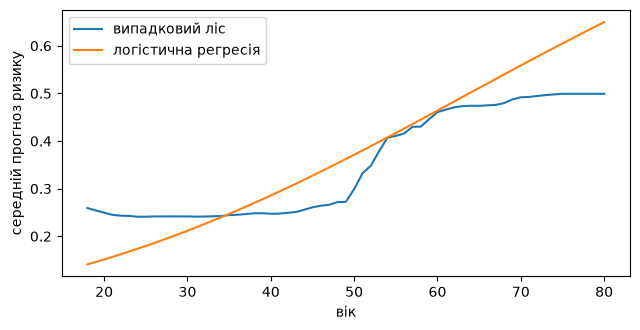

ліс: ризик 0.259 при 18 роках, мінімум 0.241 при 24, 0.499 при 80
логістична регресія: 0.141 при 18 роках, 0.650 при 80


In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

lin = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
pd_rf = partial_dependence(model, FINAL_X, [NONLINEAR_FEATURE], kind='average')
pd_lin = partial_dependence(lin, FINAL_X, [NONLINEAR_FEATURE], kind='average')
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(pd_rf['grid_values'][0], pd_rf['average'][0], label='випадковий ліс')
ax.plot(pd_lin['grid_values'][0], pd_lin['average'][0], label='логістична регресія')
ax.set_xlabel(NONLINEAR_FEATURE)
ax.set_ylabel('середній прогноз ризику')
ax.legend()
plt.tight_layout()
plt.show()
RISK_MIN_AT = float(pd_rf['grid_values'][0][np.argmin(pd_rf['average'][0])])
print('ліс: ризик %.3f при %.0f роках, мінімум %.3f при %.0f, %.3f при %.0f'
      % (pd_rf['average'][0][0], pd_rf['grid_values'][0][0], pd_rf['average'][0].min(), RISK_MIN_AT,
         pd_rf['average'][0][-1], pd_rf['grid_values'][0][-1]))
print('логістична регресія: %.3f при %.0f роках, %.3f при %.0f'
      % (pd_lin['average'][0][0], pd_lin['grid_values'][0][0], pd_lin['average'][0][-1], pd_lin['grid_values'][0][-1]))

In [39]:
NONLINEAR_MEANING = ('найменше йдуть клієнти близько %.0f років, молодші трохи частіше, а з віком ризик різко росте, '
                     'до %.3f у %.0f проти %.3f у мінімумі, тобто найризиковіші старші абоненти' % (RISK_MIN_AT, pd_rf['average'][0][-1],
                                                                                         pd_rf['grid_values'][0][-1], pd_rf['average'][0].min()))
NONLINEAR_FIX = ('ознака (вік − %.0f)², квадрат відхилення від віку з найнижчим ризиком: з нею лінійна модель отримує і спад, і зростання' % RISK_MIN_AT)
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

найменше йдуть клієнти близько 24 років, молодші трохи частіше, а з віком ризик різко росте, до 0.499 у 80 проти 0.241 у мінімумі, тобто найризиковіші старші абоненти
ознака (вік − 24)², квадрат відхилення від віку з найнижчим ризиком: з нею лінійна модель отримує і спад, і зростання


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
Xq = FINAL_X.assign(вік_відхилення_кв=(FINAL_X[NONLINEAR_FEATURE] - RISK_MIN_AT) ** 2)
lin_base = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
lin_quad = cross_val_score(make_pipe(Xq, logreg()), Xq, y, cv=cv, scoring='roc_auc')
quad_m, quad_h = paired(lin_base, lin_quad)
print('логістична регресія: AUC %.3f без нової ознаки, %.3f з нею; різниця %+.4f ± %.4f, %s'
      % (lin_base.mean(), lin_quad.mean(), quad_m, quad_h, 'значуще' if abs(quad_m) > quad_h else 'у межах шуму'))

логістична регресія: AUC 0.838 без нової ознаки, 0.855 з нею; різниця +0.0169 ± 0.0042, значуще


In [41]:
QUAD_GAIN = quad_m
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0169


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

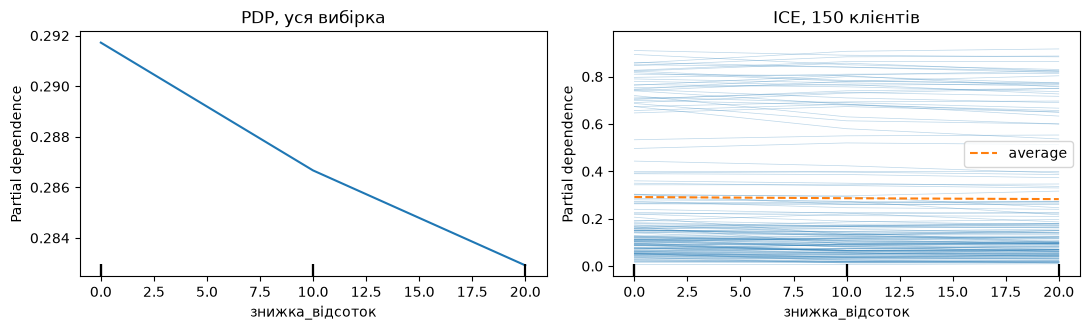

PDP по всій вибірці: {np.int64(0): np.float64(0.292), np.int64(10): np.float64(0.287), np.int64(20): np.float64(0.283)}
ICE: від знижки 0 до 20 % ризик росте в 0.256 клієнтів, падає в 0.460


In [42]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
d1 = PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=ax[0])
d2 = PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='both',
                                             subsample=150, random_state=SEED, ax=ax[1])
d1.axes_[0, 0].set_title('PDP, уся вибірка')
d2.axes_[0, 0].set_title('ICE, 150 клієнтів')
plt.tight_layout()
plt.show()

pdp_all = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')['individual'][0]
slope = ice[:, -1] - ice[:, 0]
print('PDP по всій вибірці:', dict(zip(pdp_all['grid_values'][0].astype(int), pdp_all['average'][0].round(3))))
print('ICE: від знижки 0 до 20 %% ризик росте в %.3f клієнтів, падає в %.3f' % ((slope > 0.01).mean(), (slope < -0.01).mean()))

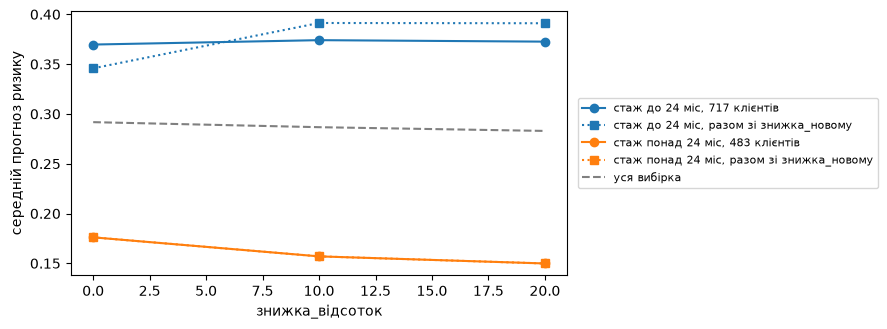

,стаж до 24 міс,"стаж до 24 міс, обидві ознаки разом",стаж понад 24 міс,"стаж понад 24 міс, обидві ознаки разом"
знижка,,,,
0,0.370,0.346,0.176,0.176
10,0.374,0.391,0.157,0.157
20,0.373,0.391,0.150,0.150


In [43]:
LONG = 24
groups = {'стаж до 24 міс': FINAL_X['місяців_обслуговування'] <= LONG,
          'стаж понад 24 міс': FINAL_X['місяців_обслуговування'] > LONG}
grid_d = pdp_all['grid_values'][0]

def joint_pdp(X):
    out = []
    for v in grid_d:
        Z = X.copy()
        Z['знижка_відсоток'] = v
        Z['знижка_новому'] = v * Z['перші_24_місяці']
        out.append(model.predict_proba(Z)[:, 1].mean())
    return np.array(out)

pdp_groups = {}
fig, ax = plt.subplots(figsize=(9, 3.4))
for (name, mask), colour in zip(groups.items(), ['#1f77b4', '#ff7f0e']):
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    pdp_groups[name] = r['average'][0]
    pdp_groups[name + ', обидві ознаки разом'] = joint_pdp(FINAL_X[mask])
    ax.plot(grid_d, pdp_groups[name], marker='o', color=colour, label='%s, %d клієнтів' % (name, mask.sum()))
    ax.plot(grid_d, pdp_groups[name + ', обидві ознаки разом'], ls=':', marker='s', color=colour,
            label='%s, разом зі знижка_новому' % name)
ax.plot(grid_d, pdp_all['average'][0], ls='--', color='grey', label='уся вибірка')
ax.set_xlabel('знижка_відсоток')
ax.set_ylabel('середній прогноз ризику')
ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()
pdp_groups = pd.DataFrame(pdp_groups, index=grid_d.astype(int)).rename_axis('знижка').round(3)
display(pdp_groups)

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
tenure = np.where(raw['місяців_обслуговування'] <= LONG, 'стаж до 24 міс', 'стаж понад 24 міс')
emp = raw.pivot_table(index='знижка_відсоток', columns=tenure, values=TARGET, aggfunc=['mean', 'size']).round(3)
emp.columns = ['відтік, ' + b if a == 'mean' else 'клієнтів, ' + b for a, b in emp.columns]
display(emp)

,"відтік, стаж до 24 міс","відтік, стаж понад 24 міс","клієнтів, стаж до 24 міс","клієнтів, стаж понад 24 міс"
знижка_відсоток,,,,
0,0.296,0.212,307,189
10,0.423,0.138,220,167
20,0.458,0.071,190,127


In [45]:
e_new = emp['відтік, стаж до 24 міс']
e_old = emp['відтік, стаж понад 24 міс']
j_new = pdp_groups['стаж до 24 міс, обидві ознаки разом']
INTERACTION_FOUND = ('знижка діє в різні боки: у клієнтів зі стажем понад 24 місяці відтік спадає з %.3f без знижки до %.3f при 20 %%, '
                     'а в новіших зростає з %.3f до %.3f, тому PDP по всій вибірці пласкій (%.3f і %.3f); ліс це відтворює, але для нових '
                     'клієнтів через окрему ознаку знижка_новому, тож зростання видно лише при узгодженій зміні обох (%.3f і %.3f)'
                     % (e_old[0], e_old[20], e_new[0], e_new[20], pdp_all['average'][0][0], pdp_all['average'][0][-1], j_new[0], j_new[20]))
BUSINESS_ACTION = ('знижку як засіб утримання пропонувати давнім клієнтам, у яких вона йде разом із меншим відтоком, '
                   'а новим не давати автоматично: у них знижка йде разом із вищим відтоком, і для них треба шукати іншу причину й інший засіб')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

знижка діє в різні боки: у клієнтів зі стажем понад 24 місяці відтік спадає з 0.212 без знижки до 0.071 при 20 %, а в новіших зростає з 0.296 до 0.458, тому PDP по всій вибірці пласкій (0.292 і 0.283); ліс це відтворює, але для нових клієнтів через окрему ознаку знижка_новому, тож зростання видно лише при узгодженій зміні обох (0.346 і 0.391)
знижку як засіб утримання пропонувати давнім клієнтам, у яких вона йде разом із меншим відтоком, а новим не давати автоматично: у них знижка йде разом із вищим відтоком, і для них треба шукати іншу причину й інший засіб


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 81)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

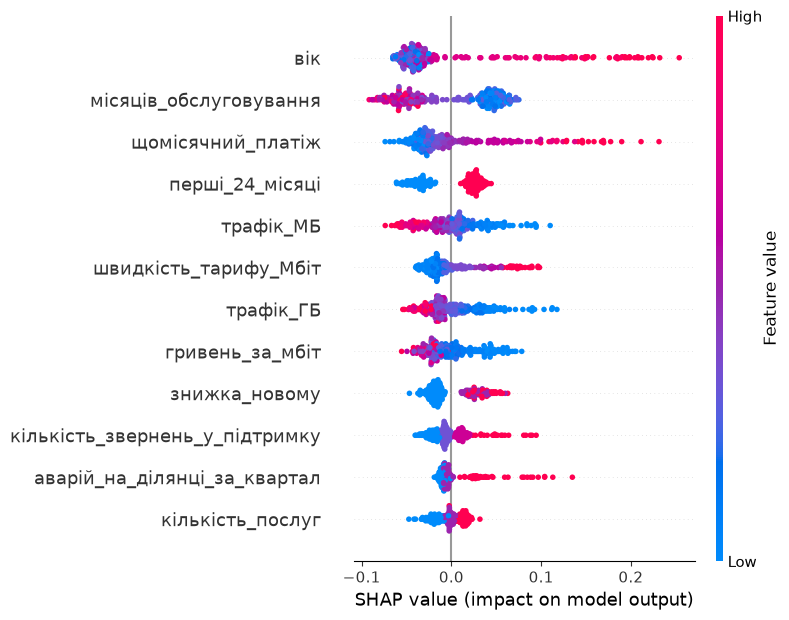

середній |внесок| за вихідними ознаками, топ-6: {'вік': 0.06, 'місяців_обслуговування': 0.048, 'щомісячний_платіж': 0.039, 'код_тарифного_плану': 0.03, 'перші_24_місяці': 0.03, 'трафік_МБ': 0.025}


In [47]:
short = [n.split('__', 1)[1] for n in feat_names]
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=short, max_display=12, show=False)
plt.tight_layout()
plt.show()
mean_abs = pd.Series(np.abs(sv1).mean(axis=0), index=owner).groupby(level=0).sum().sort_values(ascending=False)
print('середній |внесок| за вихідними ознаками, топ-6:', mean_abs.head(6).round(3).to_dict())

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

top_pos = np.argsort(-np.abs(sv1[idx]))[:3]
base_value = float(np.ravel(expl.expected_value)[-1])
display(pd.DataFrame({'стовпець після обробки': [short[i] for i in top_pos],
                      'внесок': np.round(sv1[idx][top_pos], 3)}))
display(Xte.iloc[idx][list(dict.fromkeys(owner[i] for i in top_pos))].to_frame('значення в клієнта'))
print('базовий рівень %.3f + сума внесків %.3f = %.3f' % (base_value, sv1[idx].sum(), base_value + sv1[idx].sum()))

ризик клієнта: 0.887


,стовпець після обробки,внесок
0,щомісячний_платіж,0.128
1,вік,0.124
2,швидкість_тарифу_Мбіт,0.077


,значення в клієнта
щомісячний_платіж,649.42
вік,60.0
швидкість_тарифу_Мбіт,1000.0


базовий рівень 0.285 + сума внесків 0.601 = 0.887


In [49]:
client = Xte.iloc[idx]
pay_share = (FINAL_X['щомісячний_платіж'] < client['щомісячний_платіж']).mean()
EXPLANATION_FOR_MANAGER = ('Ризик, що цей абонент розірве договір протягом кварталу, оцінено в %.0f %% проти %.0f %% у середньому. '
                           'Найбільше його підіймають три речі: він платить %.0f грн на місяць, більше ніж %.0f %% абонентів, '
                           'йому %.0f років, а старші абоненти відходять помітно частіше, і він на тарифі %.0f Мбіт, одному з найшвидших. '
                           'Розмову варто почати з того, чи вартий цей тариф своїх грошей саме для нього.'
                           % (100 * model.predict_proba(Xte)[:SAMPLE, 1][idx], 100 * base_value, client['щомісячний_платіж'],
                              100 * pay_share, client['вік'], client['швидкість_тарифу_Мбіт']))
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Ризик, що цей абонент розірве договір протягом кварталу, оцінено в 89 % проти 29 % у середньому. Найбільше його підіймають три речі: він платить 649 грн на місяць, більше ніж 94 % абонентів, йому 60 років, а старші абоненти відходять помітно частіше, і він на тарифі 1000 Мбіт, одному з найшвидших. Розмову варто почати з того, чи вартий цей тариф своїх грошей саме для нього.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'вік'
SHAP_NOT_CAUSAL_WHY = ('вік має найбільший середній внесок за Шеплі (%.3f) і в найризикованішого клієнта стоїть серед перших трьох, '
                       'але змінити його неможливо, а якби й було можливо, нічого б не дало: Шеплі показують, що модель користується віком, '
                       'бо серед старших абонентів більше тих, хто пішов, а не що вік спричиняє відтік; за ним можуть стояти переїзд, '
                       'складність із технікою чи інша причина, якої в даних немає, і дія має бути спрямована на неї' % mean_abs['вік'])
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

вік — вік має найбільший середній внесок за Шеплі (0.060) і в найризикованішого клієнта стоїть серед перших трьох, але змінити його неможливо, а якби й було можливо, нічого б не дало: Шеплі показують, що модель користується віком, бо серед старших абонентів більше тих, хто пішов, а не що вік спричиняє відтік; за ним можуть стояти переїзд, складність із технікою чи інша причина, якої в даних немає, і дія має бути спрямована на неї


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",вік,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
period = np.where(source == 1, 'з 2024-04-01', 'до 2024-04-01')
ap = raw.pivot_table(index='автоплатіж', columns=period, values=TARGET, aggfunc='mean')
ap['усі разом'] = raw.groupby('автоплатіж')[TARGET].mean()
display(ap.round(3))
gap = (ap.loc['ні'] - ap.loc['так']) * 100
FIFTH_MISTAKE = ('автоплатіж: у сирих даних відтік без нього %.3f, з ним %.3f, різниця лише %.1f пункту, і звідси легко прочитати «автоплатіж майже не діє», '
                 'а перестановочна важливість %+.4f це ніби підтверджує; але всередині кожного періоду різниця %.1f і %.1f пункту, '
                 'бо після зміни правила обліку автоплатіж мають %.3f клієнтів проти %.3f до неї, і високий відтік нового періоду ховає ефект, '
                 'тобто ознака корелює з артефактом збору і її вплив занижено'
                 % (ap.loc['ні', 'усі разом'], ap.loc['так', 'усі разом'], gap['усі разом'], perm_imp['автоплатіж'],
                    gap['до 2024-04-01'], gap['з 2024-04-01'], mix.loc['з 2024-04-01', 'автоплатіж'], mix.loc['до 2024-04-01', 'автоплатіж']))
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

,до 2024-04-01,з 2024-04-01,усі разом
автоплатіж,,,
ні,0.232,0.451,0.294
так,0.186,0.382,0.277


автоплатіж: у сирих даних відтік без нього 0.294, з ним 0.277, різниця лише 1.7 пункту, і звідси легко прочитати «автоплатіж майже не діє», а перестановочна важливість -0.0002 це ніби підтверджує; але всередині кожного періоду різниця 4.6 і 6.9 пункту, бо після зміни правила обліку автоплатіж мають 0.614 клієнтів проти 0.422 до неї, і високий відтік нового періоду ховає ефект, тобто ознака корелює з артефактом збору і її вплив занижено


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
TOP_N = 100
risk = model.predict_proba(Xte)[:, 1]
top = yte.iloc[np.argsort(-risk)[:TOP_N]]
lift = top.mean() / yte.mean()
print('у топ-%d пішли %d клієнтів, частка %.3f; у всій перевірковій частині (%d клієнтів) %.3f; lift %.2f'
      % (TOP_N, top.sum(), top.mean(), len(yte), yte.mean(), lift))
print('навмання серед %d клієнтів було б у середньому %.1f тих, хто піде' % (TOP_N, TOP_N * yte.mean()))

у топ-100 пішли 69 клієнтів, частка 0.690; у всій перевірковій частині (360 клієнтів) 0.286; lift 2.41
навмання серед 100 клієнтів було б у середньому 28.6 тих, хто піде


In [54]:
LIFT_MEANING = ('список із %d найризикованіших містить у %.2f раза більше тих, хто справді піде, ніж %d навмання обраних: %d проти %.1f'
                % (TOP_N, lift, TOP_N, top.sum(), TOP_N * yte.mean()))
assert LIFT_MEANING
print(LIFT_MEANING)

список із 100 найризикованіших містить у 2.41 раза більше тих, хто справді піде, ніж 100 навмання обраних: 69 проти 28.6


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_06.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
sc = scan.set_index('ознака')['показник']
t = cmp_models['с на 100 навчань']
age_c = sv1[idx][[i for i, o in enumerate(owner) if o == 'вік']].sum()
q = by_quarter['відтік']
A = [
    '1. Обрав AUC, бо відтік у моїх даних %.3f, і модель «ніхто не піде» мала б точність %.3f, не знайшовши жодного клієнта, який іде, '
    'а AUC не залежить від порога й оцінює саме порядок, у якому клієнтів поставлено за ризиком, тоді як відділу утримання потрібен список, '
    'відсортований за ризиком.' % (y.mean(), 1 - y.mean()),

    '2. Викинув п’ять стовпців. id_клієнта з’являється при укладанні договору, але нічого не пояснює, лише дає себе запам’ятати. '
    'дата_розірвання і сума_повернення_депозиту з’являються в день розірвання і після закриття договору, детектор дав обом %.3f, бо вони '
    'заповнені лише в тих, хто пішов, але їх вилучення AUC майже не змінило: %.3f до і %.3f після. оцінка_ризику_менеджером з’являється, коли менеджер '
    'уже бачив поведінку клієнта; детектор її не знайшов, бо вона заповнена в усіх %d клієнтів і групи пропусків немає, а після її вилучення '
    'AUC упала з %.3f до %.3f. дата_підключення відома з першого дня, але викинута як артефакт збору, бо в ній закодоване правило обліку, '
    'яке змінилося у квітні 2024 року.' % (sc['дата_розірвання'], auc_naive.mean(), auc2.mean(), len(raw), auc2.mean(), auc3.mean()),

    '3. Чесне число %.3f ± %.3f: логістична регресія на %d ознаках без витоку і без дати підключення, середнє з 20 навчань схеми 5×4. '
    'Розкид у %.1f раза більший за 0,004, тому дві моделі, що відрізняються на 0,004, за середніми порівнювати не можна, лише парно на тих самих згортках; '
    'так ліс показав %+.4f ± %.4f, а бустинг %+.4f ± %.4f, тобто в межах шуму.'
    % ((auc4.mean(), auc4.std(), X4.shape[1], auc4.std() / 0.004) + gains['випадковий ліс'] + gains['гістограмний бустинг']),

    '4. Артефакт є, і сидить він у даті підключення, а не у філії. Відтік клієнтів, підключених до квітня 2024 року, за кварталами від %.3f до %.3f, '
    'а з 2024Q2 стрибком від %.3f до %.3f, і ті самі чесні ознаки вгадують, чи підключений клієнт після зламу, з AUC %.3f, бо нові клієнти беруть '
    'інші тарифи: швидкість від 400 Мбіт у %.3f проти %.3f, оптика %.3f проти %.3f, автоплатіж %.3f проти %.3f. За філіями сходинки немає, '
    'відтік від %.3f до %.3f, тож в іншій філії моделі можна довіряти приблизно так само, а от на клієнтах, облікованих за іншим правилом, '
    'ні, бо частину сигналу швидкості й автоплатежу модель бере з періоду, а не з поведінки.'
    % (q[:'2024Q1'].min(), q[:'2024Q1'].max(), q['2024Q2':].min(), q['2024Q2':].max(), auc_src.mean(),
       mix.iloc[1, 0], mix.iloc[0, 0], mix.iloc[1, 1], mix.iloc[0, 1], mix.iloc[1, 2], mix.iloc[0, 2],
       by_branch['відтік'].min(), by_branch['відтік'].max()),

    '5. Більше дали нові ознаки: три ознаки підняли AUC логістичної регресії з %.3f до %.3f, на %+.4f ± %.4f, а заміна регресії на ліс без нових ознак '
    'дала %+.4f ± %.4f, бустинг %+.4f ± %.4f. Приріст від ознак у %.1f раза більший і нічого не коштує в часі: 20 навчань регресії тривали %.1f с, '
    'лісу %.1f с, бустингу %.1f с. Найсильніша з нових ознак знижка_новому, вона і в лісі третя за перестановочною важливістю (%.4f).'
    % ((auc4.mean(), auc5.mean()) + feat_gain + gains['випадковий ліс'] + gains['гістограмний бустинг']
       + (feat_gain[0] / gains['випадковий ліс'][0], t['логістична регресія'], t['випадковий ліс'], t['гістограмний бустинг'],
          perm_imp['знижка_новому'])),

    '6. Вбудована важливість помилково назвала важливим код_тарифного_плану: %d-ге місце (%.4f) одразу після віку при перестановочній %+.4f. '
    'Дерево обирає розбиття, яке найбільше зменшує неоднорідність на навчальних даних, а %d рівнів коду після одиничного кодування дають стільки ж '
    'дамі-стовпців і спроб знайти випадково вдалий поділ; ці дрібні виграші сумуються, хоча на перевірковій частині перемішування коду якість не погіршує. '
    'Слабше та сама пастка видна на скоринг_партнера: %d різних значень, вбудована %.4f, перестановочна %+.4f.'
    % (fake_rank, imp.loc[FAKE_IMPORTANT, 'вбудована'], imp.loc[FAKE_IMPORTANT, 'перестановочна'], FINAL_X[FAKE_IMPORTANT].nunique(),
       FINAL_X['скоринг_партнера'].nunique(), imp.loc['скоринг_партнера', 'вбудована'], imp.loc['скоринг_партнера', 'перестановочна']),

    '7. трафік_ГБ і трафік_МБ корельовані з r = %.4f, і в повній моделі мають перестановочну важливість лише %+.4f і %+.4f; коли я прибрав трафік_МБ '
    'і перенавчив ліс, важливість трафік_ГБ зросла до %+.4f, у %.1f раза. Це не вада методу: він відповідає, наскільки гірше без однієї ознаки, '
    'а без однієї з пари не втрачається нічого, бо той самий трафік модель бере з другої колонки; хибний лише висновок «майже нуль, отже обидві можна викинути».'
    % (pairs[0][2], perm_imp[DUP_PAIR[0]], perm_imp[DUP_PAIR[1]], dup_alone, dup_alone / perm_imp[DUP_PAIR[0]]),

    '8. Немонотонний вплив має вік: у лісу ризик спадає з %.3f у %.0f років до %.3f у %.0f і далі зростає до %.3f у %.0f. Логістична регресія без втручання '
    'цього не побачила б, бо її крива на тому самому графіку лише зростає, з %.3f до %.3f. Ознака (вік − %.0f)² підняла AUC регресії з %.3f до %.3f, '
    'на %+.4f ± %.4f, і це значущо.'
    % (pd_rf['average'][0][0], pd_rf['grid_values'][0][0], pd_rf['average'][0].min(), RISK_MIN_AT, pd_rf['average'][0][-1],
       pd_rf['grid_values'][0][-1], pd_lin['average'][0][0], pd_lin['average'][0][-1], RISK_MIN_AT, lin_base.mean(), lin_quad.mean(),
       quad_m, quad_h),

    '9. PDP збрехав на знижці: по всій вибірці середній ризик %.3f без знижки і %.3f при 20 %%, і з цього легко прочитати «знижка не діє». '
    'ICE показав, що криві йдуть у різні боки, від знижки 0 до 20 %% ризик зростає в %.3f клієнтів і падає в %.3f. У сирих даних у клієнтів '
    'зі стажем понад 24 місяці відтік спадає з %.3f до %.3f, а в новіших зростає з %.3f до %.3f, і протилежні ефекти гасять один одного в середньому. '
    'PDP по групах показує спад для давніх (%.3f і %.3f), а для нових ефект ліс несе окремою ознакою знижка_новому, тому зростання (%.3f і %.3f) видно, '
    'лише коли міняти обидві ознаки разом.'
    % (pdp_all['average'][0][0], pdp_all['average'][0][-1], (slope > 0.01).mean(), (slope < -0.01).mean(),
       e_old[0], e_old[20], e_new[0], e_new[20], pdp_groups.loc[0, 'стаж понад 24 міс'], pdp_groups.loc[20, 'стаж понад 24 міс'],
       j_new[0], j_new[20]),

    '10. Вік має найбільший середній внесок за Шеплі, %.3f, а в найризикованішого клієнта додає %+.3f до оцінки, але втручання в нього неможливе '
    'і нічого б не дало. Шеплі показують, як модель користується ознакою: серед старших абонентів більше тих, хто пішов, і модель це запам’ятала. '
    'Причиною вік від цього не стає, за ним може стояти переїзд, складність із технікою чи інше, чого в даних немає, і діяти треба саме на ту причину.'
    % (mean_abs['вік'], age_c),

    '11. Замовникові скажу: обдзвоніть 100 клієнтів із найвищим ризиком; у перевірці серед них пішли %d, у %.2f раза більше, ніж серед 100 навмання '
    'обраних (%.1f), а AUC моделі на відкладеній частині %.3f. Застереження: lift каже, кого знайти, а не кого вдасться втримати, і чи допоможе дзвінок '
    'зі знижкою, з цих даних не видно; новим клієнтам знижка в наших даних іде разом із вищим відтоком, %.3f при 20 %% проти %.3f без неї, '
    'тому пропонувати знижку всім зі списку без окремої перевірки не варто.'
    % (top.sum(), lift, TOP_N * yte.mean(), auc_hold, e_new[20], e_new[0]),
]
DECLARATION = ('Декларація про використання ШІ: роботу виконано за допомогою ШІ-асистента Claude (Claude Code, модель Claude Opus 5.5, Anthropic). '
               'Асистент написав код у клітинках «ВАШ КОД», вирішив, які стовпці викинути, придумав нові ознаки і написав відповіді; '
               'числа у відповідях підставляються зі змінних ноутбука. Виконані перевірки: Restart & Run All на чистому ядрі без помилок з усіма assert; '
               'to_number проходить самоперевірку і перетворює 3 Excel-дати в трафік_ГБ на NaN, а поруч стоїть той самий трафік у МБ; '
               'уся обробка всередині конвеєра, fit поза ним не викликається; перестановочна важливість рахується на перевірковій частині; '
               'перші результати звірено з окремим скриптом поза ноутбуком. Не перевірено і є міркуванням: зміст полів, для яких немає опису '
               '(момент появи суми повернення, оцінки менеджера, скорингу партнера), причина сходинки у квітні 2024 року, гіпотези нових ознак. '
               'Три нові ознаки відібрано з шести перевірених на тій самій схемі, тож їхній приріст трохи оптимістичний.')
REPORT = '\n\n' + '\n\n'.join(A) + '\n\n' + DECLARATION + '\n'
print(REPORT)



1. Обрав AUC, бо відтік у моїх даних 0.286, і модель «ніхто не піде» мала б точність 0.714, не знайшовши жодного клієнта, який іде, а AUC не залежить від порога й оцінює саме порядок, у якому клієнтів поставлено за ризиком, тоді як відділу утримання потрібен список, відсортований за ризиком.

2. Викинув п’ять стовпців. id_клієнта з’являється при укладанні договору, але нічого не пояснює, лише дає себе запам’ятати. дата_розірвання і сума_повернення_депозиту з’являються в день розірвання і після закриття договору, детектор дав обом 1.000, бо вони заповнені лише в тих, хто пішов, але їх вилучення AUC майже не змінило: 0.977 до і 0.976 після. оцінка_ризику_менеджером з’являється, коли менеджер уже бачив поведінку клієнта; детектор її не знайшов, бо вона заповнена в усіх 1200 клієнтів і групи пропусків немає, а після її вилучення AUC упала з 0.976 до 0.829. дата_підключення відома з першого дня, але викинута як артефакт збору, бо в ній закодоване правило обліку, яке змінилося у квітні 202

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.